In [1]:
from dotenv import load_dotenv

load_dotenv()

True

#### LLM

In [2]:
from langchain_ollama import ChatOllama

llm = ChatOllama(
    model='llama3.1:latest', 
    num_predict=512,
)

#### define tools

In [3]:
from langchain_core.tools import tool

@tool
def add(a: int, b: int) -> int:  # 함수
    """숫자 a와 b를 더합니다."""
    return a+b

@tool
def multiply(a: int, b: int) -> int:  # 함수
    """숫자 a와 b를 곱합니다."""
    return a*b

In [4]:
add.invoke({'a':3, 'b':4})  # 딕셔너리로 감싸서

7

#### LLM tools 활용

```text

- Langgraph에서 제공하는 ToolNode를 활용하면 도구를 쉽게 사용할 수 있다.

```

In [5]:
from langgraph.prebuilt import ToolNode


tool_list = [add, multiply]

# 동일한 도구 리스트를 할당
llm_with_tools = llm.bind_tools(tool_list)
tool_node = ToolNode(tool_list)

In [6]:
# 테스트

# tool 에서 invoke 를 바로 했었는데 

# query = ''

multiply.invoke({'a':3, 'b':4}) 

12

```text

ToolNode

    Input Formats:
        1. **Graph state** with `messages` key that has a list of messages:
            - Common representation for agentic workflows
            - Supports custom messages key via `messages_key` parameter

        2. **Message List**: `[AIMessage(..., tool_calls=[...])]`
            - List of messages with tool calls in the last AIMessage

        3. **Direct Tool Calls**: `[{"name": "tool", "args": {...}, "id": "1", "type": "tool_call"}]`
            - Bypasses message parsing for direct tool execution
            - For programmatic tool invocation and testing

- list of messages: AnyMessage (system, ai, human, tool)
- 마지막에 AiMessage가 제일 마지막에 있어야 함
```

In [7]:
ai_messages = llm_with_tools.invoke('3 곱하기 5는?')
ai_messages  # tool_calls를 가니 

AIMessage(content='', additional_kwargs={}, response_metadata={'model': 'llama3.1:latest', 'created_at': '2026-10-14T14:51:54.2022714Z', 'done': True, 'done_reason': 'stop', 'total_duration': 22021148400, 'load_duration': 13620127500, 'prompt_eval_count': 220, 'prompt_eval_duration': 5653789000, 'eval_count': 22, 'eval_duration': 2725082000, 'logprobs': None, 'model_name': 'llama3.1:latest', 'model_provider': 'ollama'}, id='lc_run--01a13ae5-a9d0-7740-80f8-a750a527198c-0', tool_calls=[{'name': 'multiply', 'args': {'a': 3, 'b': 5}, 'id': 'bf3b0cf6-a378-4265-b8b5-382fcf0fe4e0', 'type': 'tool_call'}], invalid_tool_calls=[], usage_metadata={'input_tokens': 220, 'output_tokens': 22, 'total_tokens': 242})

In [8]:
# ToolNode 에서 바로 invoke를 할 수 있음
# tool_node.invoke({'messages' : []}) 로 호출해야 한다. 
from langgraph.runtime import Runtime

tool_node.invoke({'messages' : [ai_messages]},
                 runtime=Runtime())   # 조건을 모두 충족한다. -> List of Messages, 마지막에 ai message, tools calls 를 가진... -> invoke를 해주면 tool_message가 잘 나온다. 

{'messages': [ToolMessage(content='15', name='multiply', tool_call_id='bf3b0cf6-a378-4265-b8b5-382fcf0fe4e0')]}

In [9]:
# 그래프를 만들고 agent 로 선언

# state 선언 - messages 의 경우, 랭그래프가 내장으로 제공하는 state 가 있다. -> MessagesState
from langgraph.graph import MessagesState, StateGraph

graph_builder = StateGraph(MessagesState)


# class MessagesState(TypedDict):
#     messages: Annotated[list[AnyMessage], add_messages]
# 랭그래프의 add_messages 라는 메서드를 통해서 계속 메시지를 추가할 수 있다. 

In [10]:
# 노드 생성

# 에이전트 생성 (LLM 호출만 하는)
# message list는 llm_with_tools 가 invoke를 한다
# 에이전트 노드를 만들고, message_list를 가지고 llm_with_tools를 invoke 만 한다. 

# 사용자의 질문이 들어오면 -> messages
# add_messages -> 자동으로 메시지를 추가해준다 (append 의 역할)

In [11]:
def agent(state: MessagesState):

    messages = state['messages']
    response = llm_with_tools.invoke(messages)
    
    return {'messages':[response]}

In [12]:
# agent -- toolNode 
# 답변이 생성될 때까지 agent 가 tool을 호출하고, 답변을 주고 반복한다
# 원래 답변완료가 되었다 -> EMD 로 간다

# 조건이 있는 것 -> 정보 더 필요? 답변 완료? 
# conditional 로 분기해줄 노드가 필요하다.


In [13]:
# 도구를 호출해야 하면 aimessage 에 tool_calls 가 있음
# 답변이 만들어졌으면 content 안에 답변이 들어가고, calls 없음 이걸 기반으로 도구 사용 여부를 정하는 것
def should_continue(state: MessagesState):

    messages = state['messages']   # messages

    # 마지막 메시지를 본다. 여기서 response 가 llm_tools_invoke 결과이기 때문에 aimessage 일 것
    # ai message 안에 tool calls가 있으면 도구 호출을 해서 결과를 받아야 하는 거고 없으면 END로 
    last_ai_message = messages[-1]
    if last_ai_message.tool_calls:
        return 'tools'
    
    return 'end'


In [14]:
graph_builder.add_node('agent', agent)
graph_builder.add_node('tools', tool_node)

In [15]:
from langgraph.graph import START, END

graph_builder.add_edge(START, 'agent')
graph_builder.add_conditional_edges(
    'agent',
    should_continue,
    {
        'tools' : 'tools',
        'end' : END
    }
)
graph_builder.add_edge('tools', 'agent')

In [ ]:
# should_continue 에서 'end' -> END 로 수정 후 

# 딕셔너리 대신에 리스트로 넣어주게 되면 -> 우리가 원하느 그림이 잘 나온다 (비교해보기)

# from langgraph.graph import START, END

# graph_builder.add_edge(START, 'agent')
# graph_builder.add_conditional_edges(
#     'agent',
#     should_continue,
#     ['tools', END]
# )
# graph_builder.add_edge('tools', 'agent')

In [16]:
graph = graph_builder.compile()

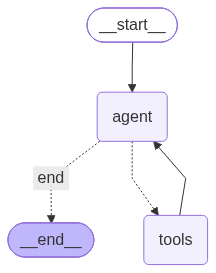

In [17]:
from IPython.display import Image, display

display(Image(graph.get_graph().draw_mermaid_png()))

In [ ]:
## 호출
from langchain_core.messages import HumanMessage

# 이번에는 messages 가 들어간다. 
# stream -> Iterator 이기 때문에 반복문을 쓰면 청크를 볼 수 있음 
for chunk in graph.stream({'messages':[HumanMessage('3에다가 5를 더하고 거기에 8을 곱하면?')]}, stream_mode='values'):  # full state를 볼 수 있음
    chunk['messages'][-1].pretty_print()


================================ Human Message =================================

3에다가 5를 더하고 거기에 8을 곱하면?
================================== Ai Message ==================================
Tool Calls:
  multiply (09e9daf4-e6cb-479f-8cb5-d2c5e2b370cb)
 Call ID: 09e9daf4-e6cb-479f-8cb5-d2c5e2b370cb
  Args:
    b: 8
    a: add(b=5, a=3)
================================= Tool Message =================================
Name: multiply

Error invoking tool 'multiply' with kwargs {'b': '8', 'a': 'add(b=5, a=3)'} with error:
 a: Input should be a valid integer, unable to parse string as an integer
 Please fix the error and try again.
================================== Ai Message ==================================
Tool Calls:
  multiply (69471732-62bf-46cc-95ee-14952397340f)
 Call ID: 69471732-62bf-46cc-95ee-14952397340f
  Args:
    b: add(b=5, a=3)
    a: 8
================================= Tool Message =================================
Name: multiply

Error invoking tool 'multiply' with kwargs {'